# 7º Datathon de Moedas Digitais FGV — Grupo 6

**Tema:** *Agentes de IA e Operações On-Chain: Risco Comportamental, Governança Pré-Assinatura e Responsabilização (Accountability)*

Este estudo investiga como a automação e o uso de agentes em operações on-chain alteram o perfil de atividade, o risco operacional e a rastreabilidade de decisões no ecossistema Ethereum. A partir da análise empírica de transações históricas (`first_order_df.csv`) enriquecidas com metadados de contratos e domínios ENS (`wallet_metadata.csv`), demonstramos a existência de uma lacuna estrutural entre a **visibilidade técnica on-chain** e a **responsabilização operacional** (*accountability*).

Para endereçar esse problema, validamos o **OONCA** (*Operador On-Chain com Apoio de IA*), um agente *read-only* de triagem pré-assinatura que combina engenharia de features comportamentais, regras determinísticas explicáveis, recomendações contrafactuais e trilha de auditoria criptográfica (`evidence_sha256`).

In [1]:
from decimal import Decimal
import json
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from app.agent.graph import analyze, batch_analyze
from app.features.wallet_behavior import compute_wallet_features
from app.ingestion.repository import DEFAULT_METADATA_PATH, DEFAULT_TX_PATH, WalletRepository
from app.ingestion.schema import ProposedOperation
from app.models.risk import RiskPolicy
from app.visualization.risk import plot_operator_dashboard

SAMPLE_TX_PATH = ROOT / "samples" / "ethereum" / "first_order_df.csv"
SAMPLE_META_PATH = ROOT / "samples" / "ethereum" / "wallet_metadata.csv"

def resolve_dataset_paths() -> tuple[Path, Path, str]:
    if DEFAULT_TX_PATH.is_file() and DEFAULT_METADATA_PATH.is_file():
        return DEFAULT_TX_PATH, DEFAULT_METADATA_PATH, "Dataset completo local (data/)"
    if SAMPLE_TX_PATH.is_file() and SAMPLE_META_PATH.is_file():
        return SAMPLE_TX_PATH, SAMPLE_META_PATH, "Amostra reprodutível de seis carteiras (não representativa)"
    raise FileNotFoundError(
        "Dados não encontrados. Baixe as fontes listadas no README ou gere a amostra com "
        "python scripts/build_reproducibility_samples.py."
    )

TX_PATH, META_PATH, DATA_SOURCE_LABEL = resolve_dataset_paths()
print("Fonte de dados ativa :", DATA_SOURCE_LABEL)
print("Arquivo de transações:", TX_PATH)
print("Arquivo de metadados :", META_PATH)

Fonte de dados ativa : Dataset completo local (data/)
Arquivo de transações: /Users/antonio/Documents/kognilabs/analytica/moedas-digitais-g6/data/Ethereum-Transactions-for-Fraud-Detection/first_order_df.csv
Arquivo de metadados : /Users/antonio/Documents/kognilabs/analytica/moedas-digitais-g6/data/wallet_metadata.csv


---
## 1. Integridade da Amostra, Deduplicação de `TxHash` e Cobertura de Metadados

A análise de dados transacionais indexados exige rigor quanto à unidade de observação:
- O conjunto `first_order_df.csv` pode conter múltiplas linhas associadas ao mesmo `TxHash` em função de indexação de eventos ou junções prévias. Para evitar viés de contagem em métricas de frequência e cadência temporal, é indispensável separar a contagem bruta de registros (`n_rows`) da contagem de transações únicas (`n_unique_tx_hashes`).
- O enriquecimento via RPC e ENS (`wallet_metadata.csv`) permite distinguir **contas externas (`eoa`)** de **contratos inteligentes (`contract`)**, adicionando contexto de contraparte apenas nas carteiras cobertas; esse metadado é posterior e não prova a identidade do operador.

In [2]:
# Leitura das colunas essenciais da base de transações e da tabela de metadados
cols = ["TxHash", "BlockHeight", "TimeStamp", "From", "To", "Value", "isError"]
tx_df = pd.read_csv(TX_PATH, usecols=cols)
tx_df["From"] = tx_df["From"].astype(str).str.lower()
tx_df["To"] = tx_df["To"].astype(str).str.lower()
tx_df["Value"] = pd.to_numeric(tx_df["Value"], errors="coerce").fillna(0.0)
tx_df["isError"] = pd.to_numeric(tx_df["isError"], errors="coerce").fillna(0).astype(int)
tx_df["dt_utc"] = pd.to_datetime(tx_df["TimeStamp"], unit="s", utc=True, errors="coerce")

meta_df = pd.read_csv(META_PATH, dtype=str)
meta_df["wallet_address"] = meta_df["wallet_address"].astype(str).str.lower()

n_total_rows = len(tx_df)
n_unique_tx = tx_df["TxHash"].nunique()
dup_rows = n_total_rows - n_unique_tx
dup_pct = (dup_rows / n_total_rows) * 100

summary_diagnostico = pd.DataFrame([
    {"Métrica da Base": "Total de linhas em first_order_df.csv", "Valor": f"{n_total_rows:,}"},
    {"Métrica da Base": "Transações únicas (TxHash distintos)", "Valor": f"{n_unique_tx:,}"},
    {"Métrica da Base": "Linhas com TxHash repetido (deduplicadas na cadência)", "Valor": f"{dup_rows:,} ({dup_pct:.2f}%)"},
    {"Métrica da Base": "Carteiras remetentes únicas (From)", "Valor": f"{tx_df['From'].nunique():,}"},
    {"Métrica da Base": "Carteiras destinatárias únicas (To)", "Valor": f"{tx_df['To'].nunique():,}"},
    {"Métrica da Base": "Início da janela temporal (UTC)", "Valor": str(tx_df['dt_utc'].min())},
    {"Métrica da Base": "Fim da janela temporal (UTC)", "Valor": str(tx_df['dt_utc'].max())},
    {"Métrica da Base": "Taxa global de erro (isError == 1)", "Valor": f"{tx_df['isError'].mean()*100:.2f}%"},
    {"Métrica da Base": "Carteiras catalogadas em wallet_metadata.csv", "Valor": f"{len(meta_df):,}"},
    {"Métrica da Base": "  └─ Contratos inteligentes (wallet_type == contract)", "Valor": f"{(meta_df['wallet_type'] == 'contract').sum():,} ({(meta_df['wallet_type'] == 'contract').mean()*100:.1f}%)"},
    {"Métrica da Base": "  └─ Carteiras EOA (wallet_type == eoa)", "Valor": f"{(meta_df['wallet_type'] == 'eoa').sum():,} ({(meta_df['wallet_type'] == 'eoa').mean()*100:.1f}%)"},
    {"Métrica da Base": "  └─ Carteiras com domínio ENS ativo observado", "Valor": f"{meta_df['ens_name'].notna().sum():,}"},
])

display(summary_diagnostico)

Métrica da Base,Valor
Total de linhas em first_order_df.csv,"254,973"
Transações únicas (TxHash distintos),"102,149"
Linhas com TxHash repetido (deduplicadas na cadência),"152,824 (59.94%)"
Carteiras remetentes únicas (From),"37,241"
Carteiras destinatárias únicas (To),"13,392"
Início da janela temporal (UTC),2016-11-30 15:47:25+00:00
Fim da janela temporal (UTC),2019-05-18 01:10:36+00:00
Taxa global de erro (isError == 1),6.13%
Carteiras catalogadas em wallet_metadata.csv,500
└─ Contratos inteligentes (wallet_type == contract),43 (8.6%)


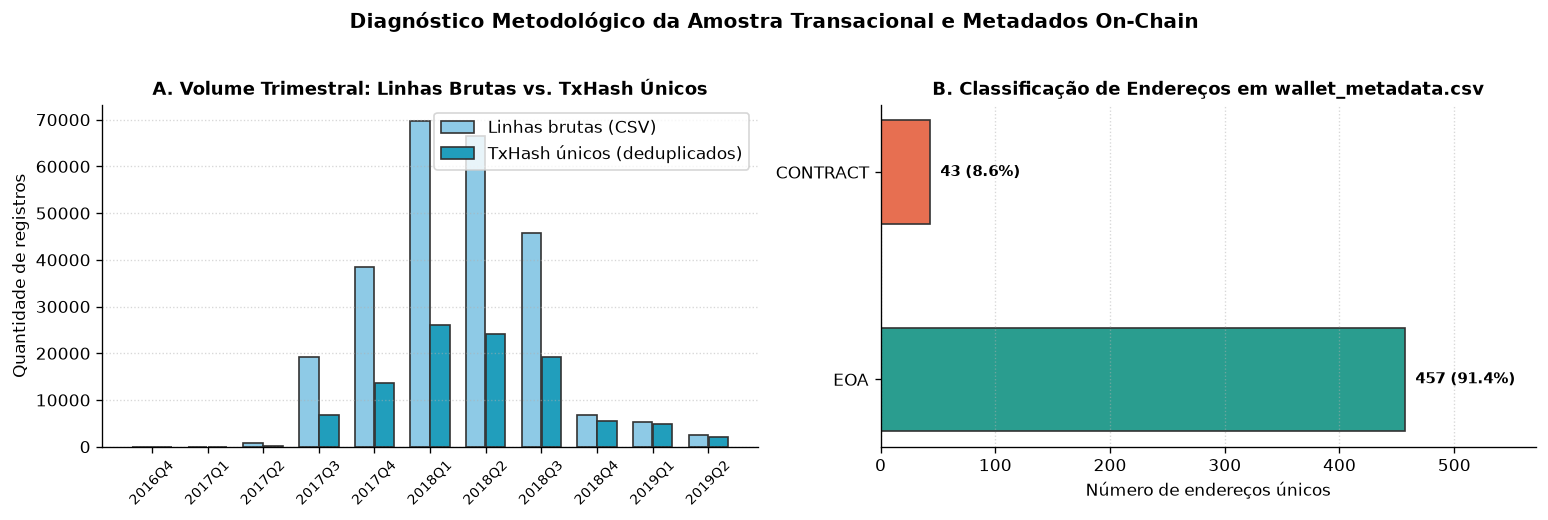

In [3]:
# Evolução Temporal da Amostra e Proporção de Tipos de Carteira / Duplicidade
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

tx_df["year_quarter"] = tx_df["dt_utc"].dt.to_period("Q").astype(str)
q_stats = tx_df.groupby("year_quarter").agg(
    linhas_brutas=("TxHash", "count"),
    tx_unicas=("TxHash", "nunique"),
    erros=("isError", "sum"),
).reset_index()

x = np.arange(len(q_stats))
axes[0].bar(x - 0.18, q_stats["linhas_brutas"], width=0.35, label="Linhas brutas (CSV)", color="#8ecae6", edgecolor="#333")
axes[0].bar(x + 0.18, q_stats["tx_unicas"], width=0.35, label="TxHash únicos (deduplicados)", color="#219ebc", edgecolor="#333")
axes[0].set_xticks(x)
axes[0].set_xticklabels(q_stats["year_quarter"], rotation=45, fontsize=8.5)
axes[0].set_ylabel("Quantidade de registros")
axes[0].set_title("A. Volume Trimestral: Linhas Brutas vs. TxHash Únicos", fontweight="bold", fontsize=10.5)
axes[0].legend(frameon=True)
axes[0].grid(axis="y", linestyle=":", alpha=0.5)

wt_counts = meta_df["wallet_type"].fillna("desconhecido").value_counts()
colors_wt = ["#2a9d8f" if k == "eoa" else "#e76f51" if k == "contract" else "#e9c46a" for k in wt_counts.index]
bars = axes[1].barh(wt_counts.index.str.upper(), wt_counts.values, color=colors_wt, edgecolor="#333", height=0.5)
axes[1].set_xlabel("Número de endereços únicos")
axes[1].set_title("B. Classificação de Endereços em wallet_metadata.csv", fontweight="bold", fontsize=10.5)
axes[1].set_xlim(0, wt_counts.max() * 1.25)
for b in bars:
    w = b.get_width()
    axes[1].text(w + wt_counts.max() * 0.02, b.get_y() + b.get_height()/2, f"{int(w):,} ({w/len(meta_df)*100:.1f}%)", va="center", fontweight="bold", fontsize=9)
axes[1].grid(axis="x", linestyle=":", alpha=0.5)

fig.suptitle("Diagnóstico Metodológico da Amostra Transacional e Metadados On-Chain", fontweight="bold", fontsize=12, y=1.02)
fig.tight_layout()
plt.show()

---
## 2. Assimetria de Valores e Concentração de Falhas Operacionais (`isError`)

A distribuição de valores transferidos (`Value`) exibe forte assimetria positiva (cauda longa), na qual a média aritmética supera substancialmente a mediana. Além disso, as falhas de execução (`isError == 1`) não se distribuem de maneira uniforme: concentram-se em carteiras específicas que interagem repetidamente com contratos ou submetem transações com parâmetros incompatíveis.

**Conclusão metodológica:**
- Limiares paramétricos baseados em média e desvio-padrão geram distorções severas em séries on-chain. O uso de quantis históricos individuais por carteira (`median_amount`, `p75_amount`, `p95_amount`, `iqr_amount`) — acionando revisão quando o valor proposto excede **$2 \times \text{P95}$ histórico** — e a exigência de um denominador mínimo de observações ($\ge 20$ transações) para julgar a taxa de erro (`historical_error_rate`) reduzem a sensibilidade a *outliers*, mas dependem de histórico suficiente e de limites avaliados para o contexto de uso.

Recorte,N,Média (ETH),Mediana / P50 (ETH),P75 (ETH),P95 (ETH),P99 (ETH),Máximo (ETH)
Todas as transações da amostra,254973,4.7842,0.0125,0.5000,5.5804,36.3291,25533.61
Apenas transações com Value > 0,172992,7.0514,0.2127,0.9992,10.0000,53.8056,25533.61


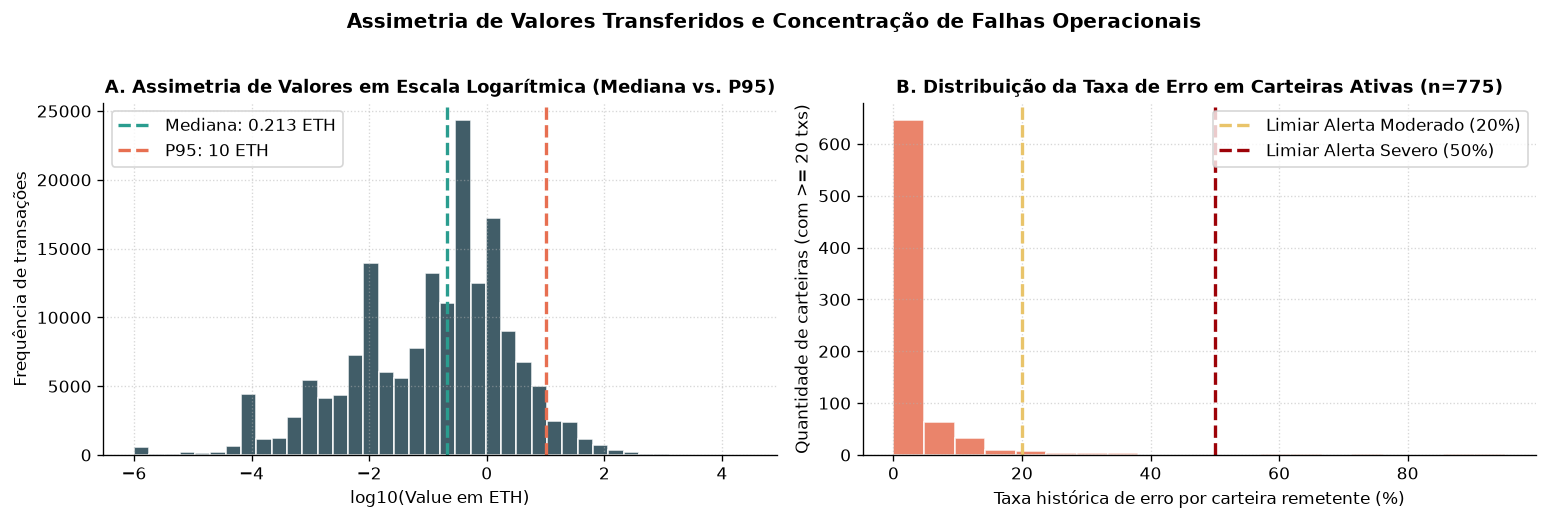

In [4]:
# Estatísticas globais de Value (todas as linhas vs. transferências com Value > 0)
nonzero_val = tx_df.loc[tx_df["Value"] > 0, "Value"]

dist_table = pd.DataFrame([
    {
        "Recorte": "Todas as transações da amostra",
        "N": len(tx_df),
        "Média (ETH)": round(float(tx_df["Value"].mean()), 4),
        "Mediana / P50 (ETH)": round(float(tx_df["Value"].median()), 4),
        "P75 (ETH)": round(float(tx_df["Value"].quantile(0.75)), 4),
        "P95 (ETH)": round(float(tx_df["Value"].quantile(0.95)), 4),
        "P99 (ETH)": round(float(tx_df["Value"].quantile(0.99)), 4),
        "Máximo (ETH)": round(float(tx_df["Value"].max()), 2),
    },
    {
        "Recorte": "Apenas transações com Value > 0",
        "N": len(nonzero_val),
        "Média (ETH)": round(float(nonzero_val.mean()), 4),
        "Mediana / P50 (ETH)": round(float(nonzero_val.median()), 4),
        "P75 (ETH)": round(float(nonzero_val.quantile(0.75)), 4),
        "P95 (ETH)": round(float(nonzero_val.quantile(0.95)), 4),
        "P99 (ETH)": round(float(nonzero_val.quantile(0.99)), 4),
        "Máximo (ETH)": round(float(nonzero_val.max()), 2),
    },
])
display(dist_table)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

log_vals = np.log10(nonzero_val.clip(lower=1e-6))
axes[0].hist(log_vals, bins=40, color="#264653", edgecolor="white", alpha=0.88)
axes[0].axvline(np.log10(nonzero_val.median()), color="#2a9d8f", linestyle="--", linewidth=2, label=f"Mediana: {nonzero_val.median():.3g} ETH")
axes[0].axvline(np.log10(nonzero_val.quantile(0.95)), color="#e76f51", linestyle="--", linewidth=2, label=f"P95: {nonzero_val.quantile(0.95):.3g} ETH")
axes[0].set_xlabel("log10(Value em ETH)")
axes[0].set_ylabel("Frequência de transações")
axes[0].set_title("A. Assimetria de Valores em Escala Logarítmica (Mediana vs. P95)", fontweight="bold", fontsize=10.5)
axes[0].legend(frameon=True)
axes[0].grid(linestyle=":", alpha=0.5)

sender_agg = tx_df.groupby("From").agg(
    n_rows=("TxHash", "count"),
    n_unique=("TxHash", "nunique"),
    err_rate=("isError", "mean"),
    total_val=("Value", "sum"),
).query("n_rows >= 20").copy()

axes[1].hist(sender_agg["err_rate"] * 100, bins=20, color="#e76f51", edgecolor="white", alpha=0.85)
axes[1].axvline(20.0, color="#e9c46a", linestyle="--", linewidth=2, label="Limiar Alerta Moderado (20%)")
axes[1].axvline(50.0, color="#9d0208", linestyle="--", linewidth=2, label="Limiar Alerta Severo (50%)")
axes[1].set_xlabel("Taxa histórica de erro por carteira remetente (%)")
axes[1].set_ylabel("Quantidade de carteiras (com >= 20 txs)")
axes[1].set_title(f"B. Distribuição da Taxa de Erro em Carteiras Ativas (n={len(sender_agg)})", fontweight="bold", fontsize=10.5)
axes[1].legend(frameon=True)
axes[1].grid(linestyle=":", alpha=0.5)

fig.suptitle("Assimetria de Valores Transferidos e Concentração de Falhas Operacionais", fontweight="bold", fontsize=12, y=1.02)
fig.tight_layout()
plt.show()

---
## 3. Engenharia de Features Comportamentais e Proxies de Automação

Sem metadados off-chain verificados, não se deve atribuir autoria por IA a uma carteira. Contudo, é possível extrair **proxies comportamentais de automação** diretamente da série temporal de transações deduplicadas por `TxHash` ([`compute_wallet_features()`](`app/features/wallet_behavior.py`)):
- **`rapid_fire_ratio`**: proporção de intervalos consecutivos com $\Delta t \le 60\text{s}$, capturando execução em velocidade sub-minuto típica de scripts e robôs;
- **`burstiness_index`**: $(\sigma_{\Delta t} - \mu_{\Delta t}) / (\sigma_{\Delta t} + \mu_{\Delta t}) \in [-1, 1]$, distinguindo cadências mecânicas periódicas ($\to -1$) de rajadas intensas de atividade ($\to +1$);
- **`hourly_entropy_normalized`**: entropia de Shannon das 24 horas UTC normalizada em $[0, 1]$, identificando carteiras que operam de forma contínua nas 24 horas do dia sem janela de repouso humano ($\ge 0.88$);
- **`recipient_hhi`**: índice Herfindahl-Hirschman ($\sum s_i^2 \in (0, 1]$) de concentração de destinatários.

**Conclusão empírica:**
- Os sinais são proxies comportamentais. Como não há rótulos confirmados de bots ou agentes de IA, não estimamos precisão ou revocação. No top 30 por atividade, o limiar demonstrativo sinaliza 27 carteiras; isso mostra que os critérios precisam de calibração e revisão humana, não que 90% sejam bots.

In [5]:
# Avaliação das 30 carteiras remetentes mais ativas por número de transações únicas
top_senders = (
    tx_df.groupby("From")["TxHash"]
    .nunique()
    .sort_values(ascending=False)
    .head(30)
    .index.tolist()
)

profiles_list = []
for wallet in top_senders:
    sub = tx_df[tx_df["From"] == wallet]
    top_to = sub["To"].mode().iloc[0] if not sub.empty else wallet
    feat = compute_wallet_features(sub, wallet, top_to, source_rows=len(tx_df))
    cad = feat["temporal_cadence"]
    auto = feat["automation_proxy"]
    profiles_list.append({
        "wallet_from": wallet[:12] + "...",
        "wallet_full": wallet,
        "n_rows": feat["n_rows"],
        "n_unique_tx": feat["n_unique_tx_hashes"],
        "n_receivers": feat["n_receivers"],
        "recipient_hhi": feat["recipient_hhi"],
        "median_eth": round(feat["median_amount"] or 0.0, 4),
        "p95_eth": round(feat["p95_amount"] or 0.0, 4),
        "error_rate_pct": round((feat["historical_error_rate"] or 0.0) * 100, 2),
        "median_dt_sec": cad["median_inter_tx_seconds"],
        "rapid_fire_pct": round((cad["rapid_fire_ratio"] or 0.0) * 100, 1),
        "burstiness": cad["burstiness_index"],
        "hourly_entropy": cad["hourly_entropy_normalized"],
        "active_hours_utc": cad["active_hours_utc"],
        "tx_per_active_day": cad["tx_per_active_day"],
        "automation_proxy_flagged": auto["flagged"],
        "automation_signals": "; ".join(auto["signals"]) if auto["signals"] else "Perfil regular / sem sinal de alta frequência",
    })

df_top_profiles = pd.DataFrame(profiles_list)
print(f"Carteiras analisadas: {len(df_top_profiles)} | Sinalizadas com Proxy de Automação: {df_top_profiles['automation_proxy_flagged'].sum()}")
display(df_top_profiles[[
    "wallet_from", "n_unique_tx", "n_receivers", "recipient_hhi",
    "rapid_fire_pct", "burstiness", "hourly_entropy", "tx_per_active_day",
    "automation_proxy_flagged", "automation_signals"
]].head(12))

Carteiras analisadas: 30 | Sinalizadas com Proxy de Automação: 27


wallet_from,n_unique_tx,n_receivers,recipient_hhi,rapid_fire_pct,burstiness,hourly_entropy,tx_per_active_day,automation_proxy_flagged,automation_signals
0xc2d7cf9564...,4122,48,0.3363,42.0,0.8777,0.9984,14.46,True,Alta cadência sub-minuto (42.0% das transações com Δt <= 60s); Atividade contínua 24h (entropia horária 1.00 em 24/24h UTC)
0xb547027a4c...,2866,245,0.0433,44.4,0.9557,0.9956,220.46,True,Alta cadência sub-minuto (44.4% das transações com Δt <= 60s); Atividade contínua 24h (entropia horária 1.00 em 24/24h UTC); Volume diário elevado (220.5 txs/dia ativo)
0xf7c00dea37...,1794,42,0.5721,23.3,0.7306,0.9979,15.88,True,Atividade contínua 24h (entropia horária 1.00 em 24/24h UTC)
0x3f5ce5fbfe...,908,355,0.0161,2.8,0.6845,0.9922,4.17,True,Atividade contínua 24h (entropia horária 0.99 em 24/24h UTC)
0x21f74c6bbc...,830,575,0.0586,3.3,0.6443,0.9625,3.32,True,Atividade contínua 24h (entropia horária 0.96 em 24/24h UTC)
0xbfa82fbe0e...,761,1,1.0000,39.9,0.8253,0.8727,26.24,True,Alta cadência sub-minuto (39.9% das transações com Δt <= 60s)
0xfbb1b73c4f...,725,312,0.0136,1.5,0.6154,0.9905,3.02,True,Atividade contínua 24h (entropia horária 0.99 em 24/24h UTC)
0x6aef2850c2...,721,137,0.5683,68.1,0.8139,0.7584,28.84,True,Alta cadência sub-minuto (68.1% das transações com Δt <= 60s)
0xd551234ae4...,701,331,0.0157,0.9,0.6271,0.9927,3.44,True,Atividade contínua 24h (entropia horária 0.99 em 24/24h UTC)
0x3cbd2e6143...,683,521,0.0097,19.7,0.8423,0.7390,24.39,False,Perfil regular / sem sinal de alta frequência


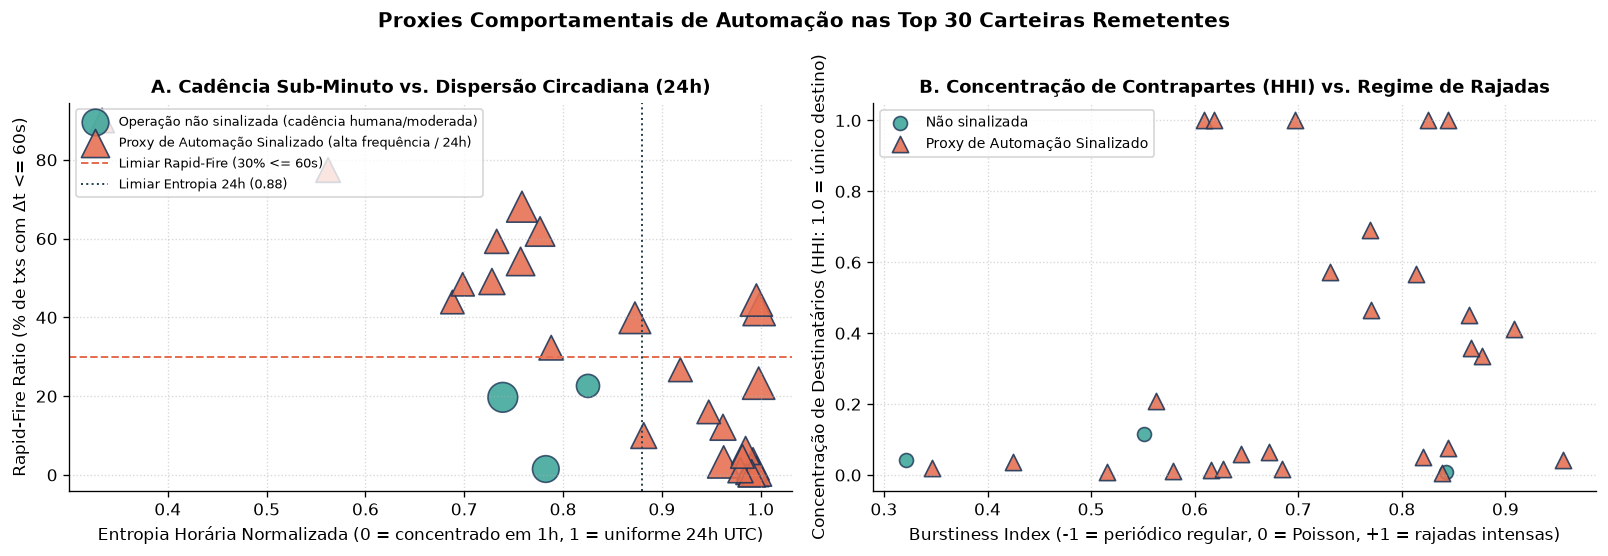

In [6]:
# Espaço Comportamental das Carteiras (Cadência Sub-Minuto vs. Entropia Horária 24h e HHI)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))

flagged_mask = df_top_profiles["automation_proxy_flagged"]

axes[0].scatter(
    df_top_profiles.loc[~flagged_mask, "hourly_entropy"],
    df_top_profiles.loc[~flagged_mask, "rapid_fire_pct"],
    s=df_top_profiles.loc[~flagged_mask, "n_unique_tx"].clip(upper=800) * 0.4 + 45,
    color="#2a9d8f", alpha=0.8, edgecolors="#1d3557", label="Operação não sinalizada (cadência humana/moderada)"
)
axes[0].scatter(
    df_top_profiles.loc[flagged_mask, "hourly_entropy"],
    df_top_profiles.loc[flagged_mask, "rapid_fire_pct"],
    s=df_top_profiles.loc[flagged_mask, "n_unique_tx"].clip(upper=800) * 0.4 + 55,
    color="#e76f51", alpha=0.88, edgecolors="#1d3557", marker="^", label="Proxy de Automação Sinalizado (alta frequência / 24h)"
)
axes[0].axhline(30.0, color="#e76f51", linestyle="--", linewidth=1.2, label="Limiar Rapid-Fire (30% <= 60s)")
axes[0].axvline(0.88, color="#264653", linestyle=":", linewidth=1.2, label="Limiar Entropia 24h (0.88)")
axes[0].set_xlabel("Entropia Horária Normalizada (0 = concentrado em 1h, 1 = uniforme 24h UTC)")
axes[0].set_ylabel("Rapid-Fire Ratio (% de txs com Δt <= 60s)")
axes[0].set_title("A. Cadência Sub-Minuto vs. Dispersão Circadiana (24h)", fontweight="bold", fontsize=10.5)
axes[0].legend(loc="upper left", fontsize=8, frameon=True)
axes[0].grid(linestyle=":", alpha=0.5)

axes[1].scatter(
    df_top_profiles.loc[~flagged_mask, "burstiness"],
    df_top_profiles.loc[~flagged_mask, "recipient_hhi"],
    s=70, color="#2a9d8f", alpha=0.8, edgecolors="#1d3557", label="Não sinalizada"
)
axes[1].scatter(
    df_top_profiles.loc[flagged_mask, "burstiness"],
    df_top_profiles.loc[flagged_mask, "recipient_hhi"],
    s=95, color="#e76f51", alpha=0.88, edgecolors="#1d3557", marker="^", label="Proxy de Automação Sinalizado"
)
axes[1].set_xlabel("Burstiness Index (-1 = periódico regular, 0 = Poisson, +1 = rajadas intensas)")
axes[1].set_ylabel("Concentração de Destinatários (HHI: 1.0 = único destino)")
axes[1].set_title("B. Concentração de Contrapartes (HHI) vs. Regime de Rajadas", fontweight="bold", fontsize=10.5)
axes[1].legend(loc="best", fontsize=8.5, frameon=True)
axes[1].grid(linestyle=":", alpha=0.5)

fig.suptitle("Proxies Comportamentais de Automação nas Top 30 Carteiras Remetentes", fontweight="bold", fontsize=12, y=1.02)
fig.tight_layout()
plt.show()

---
## 4. O "Apagão de Responsabilização" (*Accountability Gap*) em Operações On-Chain

Ao confrontar os registros públicos da blockchain com os requisitos necessários para auditar ações de agentes e operadores automatizados, evidencia-se uma assimetria estrutural:
- Os dados brutos on-chain fornecem **100% de cobertura sobre a liquidação técnica** (`wallet_from`, `wallet_to`, `Value`, `TimeStamp`, `isError`), mas **0% de cobertura sobre a camada de governança e atribuição de responsabilidade** (`operator_id`, `agent_id`, `policy_id`, `model_version`, `human_review_required` e integridade do pacote de evidências).

**Conclusão:**
- O livro-razão permite auditar a liquidação técnica, mas não registra por si só operador, modelo, política ou revisão humana. O OONCA demonstra como esses campos podem ser anexados ao pacote de decisão antes da assinatura. A cobertura de 100% mostrada na comparação é do schema demonstrativo preenchido pelo protótipo, não uma validação de identidade ou de governança institucional real.

Campo de Auditoria / Governança,CSV On-Chain Bruto (%),Com Enriquecimento ENS/RPC (%),Com Agente OONCA Pré-Assinatura (%)
wallet_from (Carteira de origem),100.0,100.0,100.0
wallet_to (Carteira de destino),100.0,100.0,100.0
sender_metadata (Tipo EOA/Contrato + ENS),0.0,100.0,100.0
recipient_metadata (Tipo EOA/Contrato + ENS),0.0,100.0,100.0
temporal_cutoff_as_of (Prevenção de Data Leakage),0.0,0.0,100.0
operator_id (Identificação da Mesa / Operador),0.0,0.0,100.0
agent_id (Identificador do Agente / Copiloto),0.0,0.0,100.0
policy_id (Política Determinística Aplicada),0.0,0.0,100.0
evidence_sha256 & human_review_required,0.0,0.0,100.0


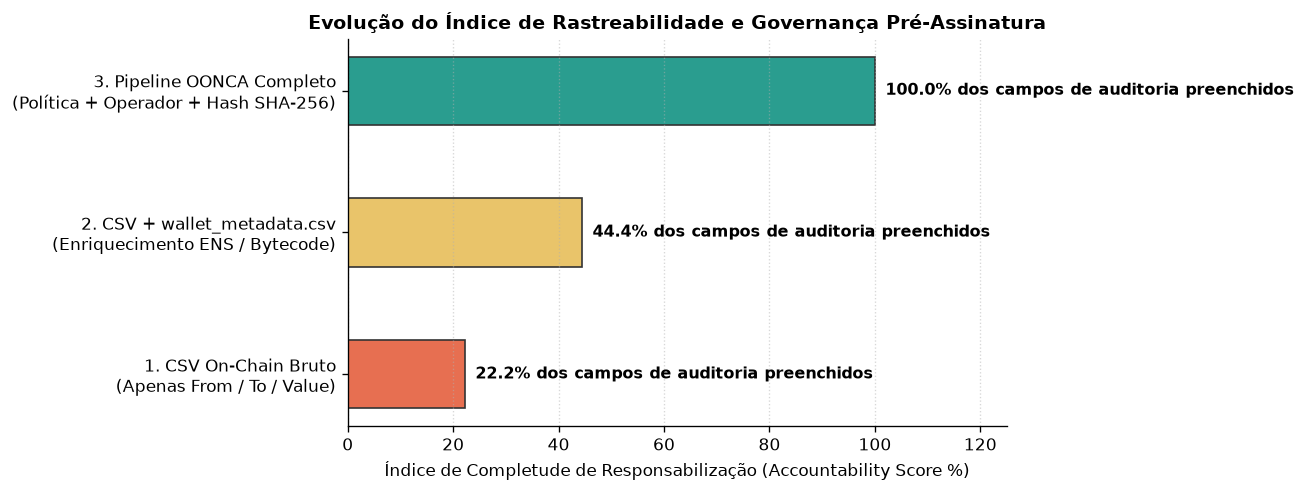

In [7]:
# Comparativo quantitativo de cobertura de campos de Governança e Responsabilização
accountability_comparison = pd.DataFrame([
    {"Campo de Auditoria / Governança": "wallet_from (Carteira de origem)", "CSV On-Chain Bruto (%)": 100.0, "Com Enriquecimento ENS/RPC (%)": 100.0, "Com Agente OONCA Pré-Assinatura (%)": 100.0},
    {"Campo de Auditoria / Governança": "wallet_to (Carteira de destino)", "CSV On-Chain Bruto (%)": 100.0, "Com Enriquecimento ENS/RPC (%)": 100.0, "Com Agente OONCA Pré-Assinatura (%)": 100.0},
    {"Campo de Auditoria / Governança": "sender_metadata (Tipo EOA/Contrato + ENS)", "CSV On-Chain Bruto (%)": 0.0, "Com Enriquecimento ENS/RPC (%)": 100.0, "Com Agente OONCA Pré-Assinatura (%)": 100.0},
    {"Campo de Auditoria / Governança": "recipient_metadata (Tipo EOA/Contrato + ENS)", "CSV On-Chain Bruto (%)": 0.0, "Com Enriquecimento ENS/RPC (%)": 100.0, "Com Agente OONCA Pré-Assinatura (%)": 100.0},
    {"Campo de Auditoria / Governança": "temporal_cutoff_as_of (Prevenção de Data Leakage)", "CSV On-Chain Bruto (%)": 0.0, "Com Enriquecimento ENS/RPC (%)": 0.0, "Com Agente OONCA Pré-Assinatura (%)": 100.0},
    {"Campo de Auditoria / Governança": "operator_id (Identificação da Mesa / Operador)", "CSV On-Chain Bruto (%)": 0.0, "Com Enriquecimento ENS/RPC (%)": 0.0, "Com Agente OONCA Pré-Assinatura (%)": 100.0},
    {"Campo de Auditoria / Governança": "agent_id (Identificador do Agente / Copiloto)", "CSV On-Chain Bruto (%)": 0.0, "Com Enriquecimento ENS/RPC (%)": 0.0, "Com Agente OONCA Pré-Assinatura (%)": 100.0},
    {"Campo de Auditoria / Governança": "policy_id (Política Determinística Aplicada)", "CSV On-Chain Bruto (%)": 0.0, "Com Enriquecimento ENS/RPC (%)": 0.0, "Com Agente OONCA Pré-Assinatura (%)": 100.0},
    {"Campo de Auditoria / Governança": "evidence_sha256 & human_review_required", "CSV On-Chain Bruto (%)": 0.0, "Com Enriquecimento ENS/RPC (%)": 0.0, "Com Agente OONCA Pré-Assinatura (%)": 100.0},
])

display(accountability_comparison)

fig, ax = plt.subplots(figsize=(10.5, 4.2))
stages = [
    "1. CSV On-Chain Bruto\n(Apenas From / To / Value)",
    "2. CSV + wallet_metadata.csv\n(Enriquecimento ENS / Bytecode)",
    "3. Pipeline OONCA Completo\n(Política + Operador + Hash SHA-256)",
]
scores_stage = [2/9 * 100, 4/9 * 100, 9/9 * 100]
bar_cols = ["#e76f51", "#e9c46a", "#2a9d8f"]

bars = ax.barh(stages, scores_stage, color=bar_cols, edgecolor="#333", height=0.48)
ax.set_xlim(0, 125)
ax.set_xlabel("Índice de Completude de Responsabilização (Accountability Score %)")
ax.set_title("Evolução do Índice de Rastreabilidade e Governança Pré-Assinatura", fontweight="bold", fontsize=11.5)
for b in bars:
    w = b.get_width()
    ax.text(w + 2, b.get_y() + b.get_height()/2, f"{w:.1f}% dos campos de auditoria preenchidos", va="center", fontweight="bold", fontsize=9.5)
ax.grid(axis="x", linestyle=":", alpha=0.5)
fig.tight_layout()
plt.show()

---
## 5. Demonstração do OONCA em Cenários Operacionais (`batch_analyze`)

Para demonstrar o fluxo de [`batch_analyze()`](`app/agent/graph.py`), avaliamos operações hipotéticas contra o histórico observado. Elas ilustram as regras configuradas; não constituem validação de detecção de fraude. A unidade de `Value` não está confirmada na documentação do dataset.

1. destino recorrente e valor abaixo do P95;
2. contrato novo e valor acima de 2 × P95;
3. carteira com proxy comportamental sinalizado;
4. carteira sem histórico (*cold start*);
5. violação do teto explícito configurado na política.

In [8]:
repo = WalletRepository(tx_path=TX_PATH, metadata_path=META_PATH)

# Caso de rotina real do dataset: destino recorrente, perfil sem proxy comportamental
# sinalizado e valor abaixo do P95 histórico.
routine_wallet = "0x3cbd2e6143f057bd49ffb4c7058217a5900c35d3"
routine_history = tx_df.loc[tx_df["From"].eq(routine_wallet)]
if routine_history.empty:
    raise ValueError("A amostra precisa incluir o histórico da carteira de rotina escolhida.")
routine_recipient = routine_history["To"].dropna().mode().iloc[0]

auto_wallet = df_top_profiles.loc[df_top_profiles["automation_proxy_flagged"], "wallet_full"].iloc[0]
auto_history = tx_df.loc[tx_df["From"].eq(auto_wallet)]
contract_candidates = meta_df.loc[meta_df["wallet_type"].eq("contract"), "wallet_address"]
known_recipients = set(routine_history["To"].dropna()) | set(auto_history["To"].dropna())
contract_candidates = contract_candidates.loc[~contract_candidates.isin(known_recipients)]
if contract_candidates.empty:
    raise ValueError("Não há contrato catalogado que seja destino inédito nos casos demonstrativos.")
contract_addr = contract_candidates.iloc[0]

cutoff = "2019-05-19T00:00:00Z"
scenarios = [
    ProposedOperation.from_values(
        wallet_from=routine_wallet, wallet_to=routine_recipient, amount="0.001",
        operator_id="mesa_tesouraria_01", as_of=cutoff,
    ),
    ProposedOperation.from_values(
        wallet_from=routine_wallet, wallet_to=contract_addr, amount="25.0",
        operator_id="mesa_tesouraria_01", as_of=cutoff,
    ),
    ProposedOperation.from_values(
        wallet_from=auto_wallet, wallet_to=contract_addr, amount="5.0",
        operator_id="bot_rebalanceador_02", as_of=cutoff,
    ),
    ProposedOperation.from_values(
        wallet_from="0x1111111111111111111111111111111111111111",
        wallet_to=routine_recipient, amount="1.0", operator_id="mesa_tesouraria_01", as_of=cutoff,
    ),
    ProposedOperation.from_values(
        wallet_from=routine_wallet, wallet_to=routine_recipient, amount="150.0",
        operator_id="mesa_tesouraria_01", as_of=cutoff,
    ),
]

policy_demo = RiskPolicy(max_amount_eth=Decimal("100.0"), review_threshold=30, policy_id="politica_tesouraria_fgv_v2")
df_scenarios = batch_analyze(scenarios, repository=repo, policy=policy_demo, use_llm=False)
df_scenarios.insert(0, "Cenário", [
    "1. Destino recorrente + valor abaixo do P95",
    "2. Novo contrato + valor acima de 2x P95",
    "3. Carteira com proxy comportamental sinalizado",
    "4. Carteira sem histórico (cold start)",
    "5. Violação do teto explícito da política",
])

display(df_scenarios[[
    "Cenário", "amount", "decision", "risk_score", "n_unique_tx_hashes",
    "recipient_seen", "automation_flagged", "human_review_required",
    "accountability_score", "reasons"
]])

Cenário,amount,decision,risk_score,n_unique_tx_hashes,recipient_seen,automation_flagged,human_review_required,accountability_score,reasons
1. Destino recorrente + valor abaixo do P95,0.001,APPROVE,10,683,True,False,False,0.8889,Destinatário identificado como contrato inteligente em operação de transferência simples
2. Novo contrato + valor acima de 2x P95,25.000,REVIEW,45,683,False,False,True,0.8889,Destino não observado anteriormente para esta carteira; Valor acima do dobro do percentil 95 histórico da carteira; Destinatário identificado como contrato inteligente em operação de transferência simples
3. Carteira com proxy comportamental sinalizado,5.000,REVIEW,90,4122,False,True,True,0.8889,"Destino não observado anteriormente para esta carteira; Alta proporção histórica de erros (71.5%); Valor acima do dobro do percentil 95 histórico da carteira; Padrão temporal compatível com automação/alta frequência (proxy comportamental): Alta cadência sub-minuto (42.0% das transações com Δt <= 60s), Atividade contínua 24h (entropia horária 1.00 em 24/24h UTC); Destinatário identificado como contrato inteligente em operação de transferência simples"
4. Carteira sem histórico (cold start),1.000,REVIEW,70,0,False,False,True,0.7778,Carteira de origem sem histórico nesta amostra; Destino não observado anteriormente para esta carteira; Tipo da carteira não coberto pelo arquivo de metadados; Destinatário identificado como contrato inteligente em operação de transferência simples
5. Violação do teto explícito da política,150.000,BLOCK,100,683,True,False,True,0.8889,Valor acima do dobro do percentil 95 histórico da carteira; Destinatário identificado como contrato inteligente em operação de transferência simples; Valor supera o limite configurado para ETH


---
## 6. Painel Visual de Evidências, Recomendações Contrafactuais e Trilha SHA-256 (`plot_operator_dashboard`)

Cada avaliação individual do OONCA sintetiza quatro dimensões críticas para o operador humano antes da assinatura:
1. **Decisão de Triagem e Termômetro Heurístico (0–100)**: confronto direto entre a pontuação acumulada e o limiar de revisão da política (`review_threshold = 30`).
2. **Decomposição Determinística de Regras**: discriminação transparente de quantos pontos cada regra acionada adicionou ao score.
3. **Comparativo do valor proposto vs. quantis históricos**: visualização imediata da distância entre o valor proposto, a mediana histórica, o P75, o P95, o limiar $2\times\text{P95}$ e o teto institucional.
4. **Proxies Comportamentais, Recomendações Contrafactuais e Governança**: indicação objetiva do que precisaria mudar para reduzir o risco da operação, acompanhada do hash criptográfico `evidence_sha256` que garante a imutabilidade da trilha de auditoria.

Explicação determinística: REVIEW (score heurístico 45/100): Destino não observado anteriormente para esta carteira; Valor acima do dobro do percentil 95 histórico da carteira; Destinatário identificado como contrato inteligente em operação de transferência simples
Recomendações contrafactuais:
  -> Confirmar endereço de destino na whitelist operacional ou verificar histórico prévio com o destinatário
  -> Reduzir o valor da operação para <= 0.0200 ETH (2x o p95 histórico da carteira) ou exigir revisão humana
  -> Verificar se o contrato destinatário aceita transferências nativas (payable fallback/receive)
Registro de Auditoria (JSON):
{
  "audit_id": "35d390f4-3f16-4ab1-bc06-5de98ea9efca",
  "evaluated_at": "2026-11-08T18:56:59.542171+00:00",
  "evidence_sha256": "33fb1419c0983a916ee53b09c9eda122d138a553815603cd47c0a3e04917b81b",
  "decision": "REVIEW",
  "risk_score": 45,
  "score_kind": "heuristic_not_probability",
  "human_review_required": true,
  "operator_id": "mesa_tesouraria_0

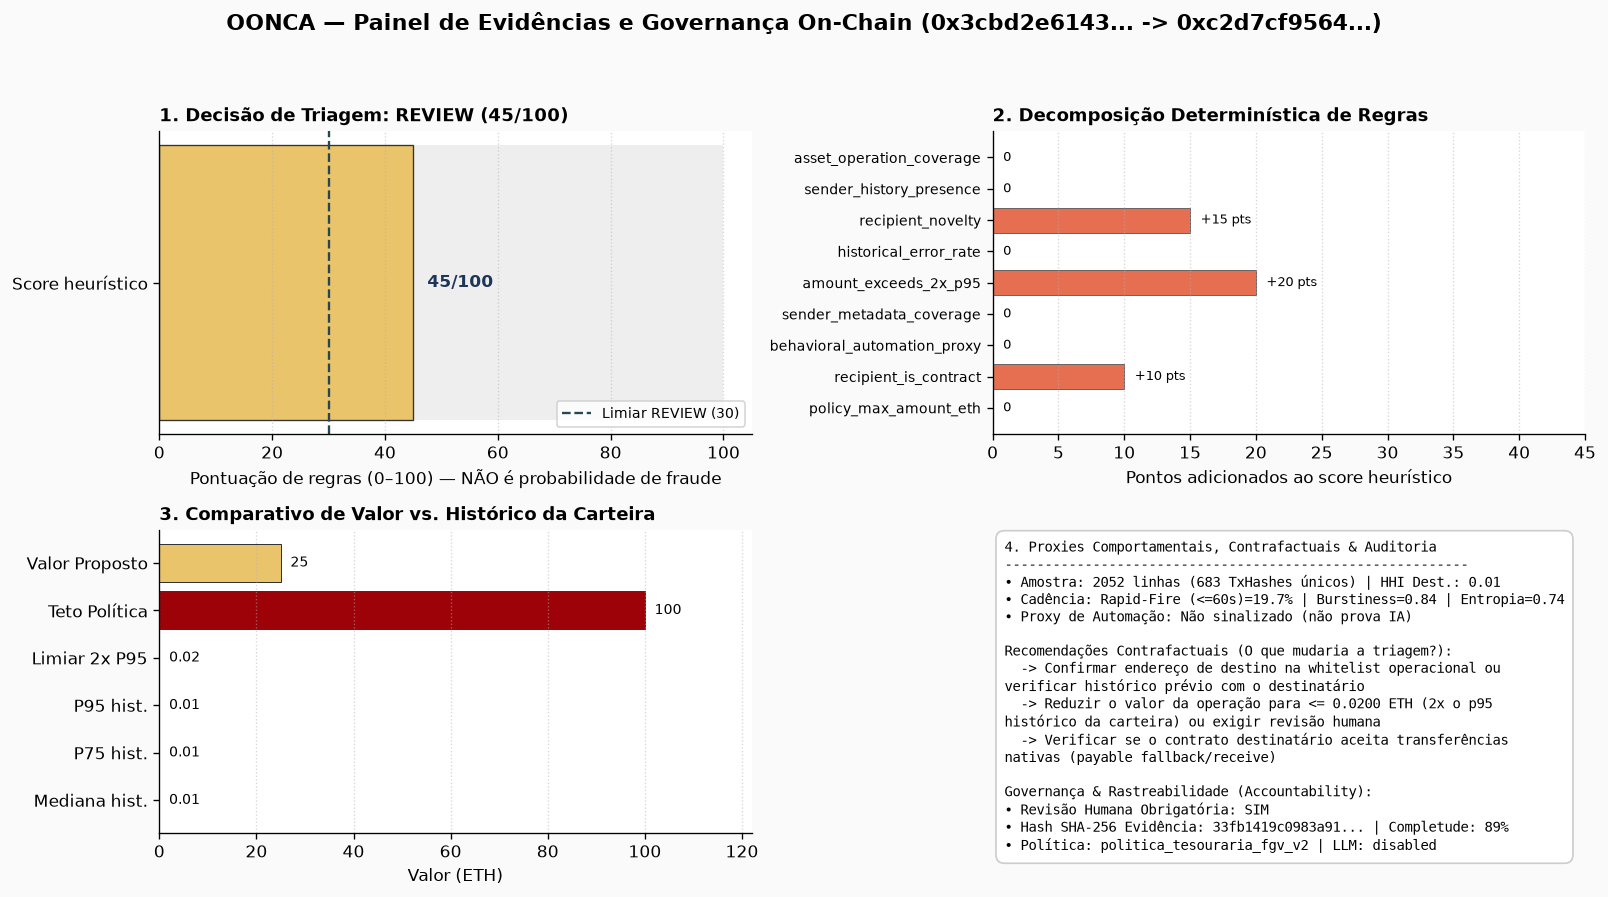

In [9]:
# Avaliação detalhada e painel visual para o Cenário 2 (Novo Destino Contrato + Valor > 2x P95)
res_review = analyze(scenarios[1], repository=repo, policy=policy_demo, use_llm=False)
print("Explicação determinística:", res_review["explanation"])
print("Recomendações contrafactuais:")
for cf in res_review["assessment"]["counterfactuals"]:
    print("  ->", cf)
print("Registro de Auditoria (JSON):")
print(json.dumps(res_review["audit_record"], indent=2, ensure_ascii=False))

fig_rev = plot_operator_dashboard(res_review)
plt.show()

Explicação determinística: REVIEW (score heurístico 90/100): Destino não observado anteriormente para esta carteira; Alta proporção histórica de erros (71.5%); Valor acima do dobro do percentil 95 histórico da carteira; Padrão temporal compatível com automação/alta frequência (proxy comportamental): Alta cadência sub-minuto (42.0% das transações com Δt <= 60s), Atividade contínua 24h (entropia horária 1.00 em 24/24h UTC); Destinatário identificado como contrato inteligente em operação de transferência simples
Sinais de Automação Detectados: {'flagged': True, 'signals': ['Alta cadência sub-minuto (42.0% das transações com Δt <= 60s)', 'Atividade contínua 24h (entropia horária 1.00 em 24/24h UTC)'], 'disclaimer': 'behavioral_proxy_not_ai_proof'}


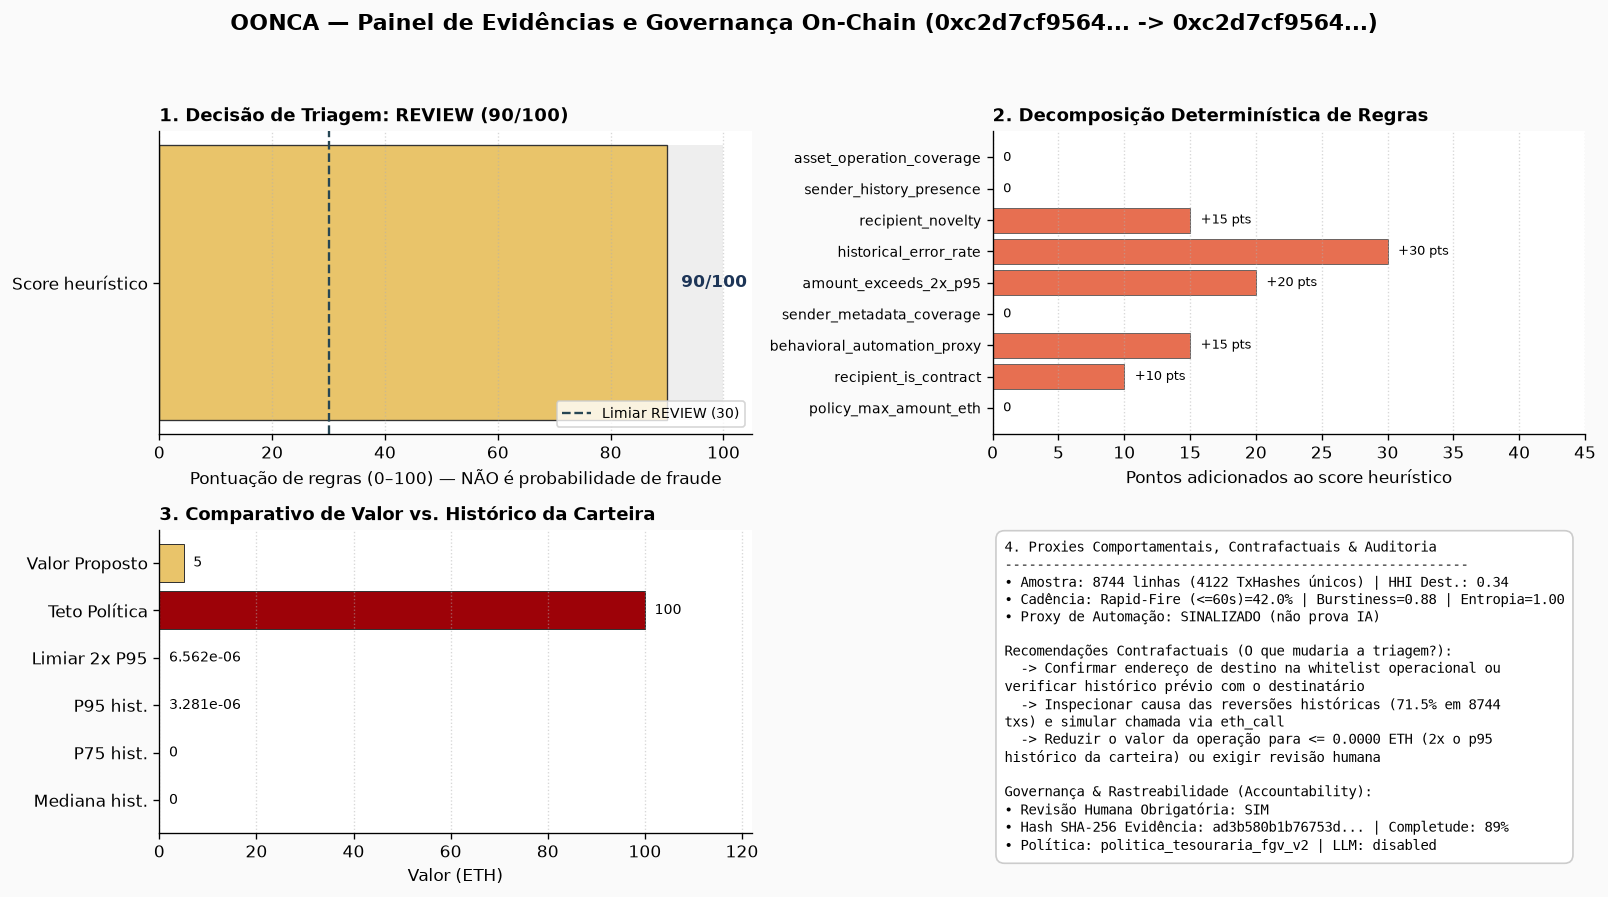

In [10]:
# Avaliação detalhada e painel visual para o Cenário 3 (Remetente com Proxy Comportamental de Automação)
res_auto = analyze(scenarios[2], repository=repo, policy=policy_demo, use_llm=False)
print("Explicação determinística:", res_auto["explanation"])
print("Sinais de Automação Detectados:", res_auto["profile"]["automation_proxy"])

fig_auto = plot_operator_dashboard(res_auto)
plt.show()

---
## 7. Conclusões Gerais e Implicações Práticas

1. **Rigor Estatístico na Triagem On-Chain:**
   - A distribuição de `Value` é assimétrica; `isError` marca falha operacional, não fraude. Quantis por carteira e contagens deduplicadas ajudam a descrever o histórico, mas os dados disponíveis não validam uma taxa de falsos positivos do agente.
2. **Distinção Metodológica entre Automação e IA:**
   - No top 30 de carteiras mais ativas, 27 foram sinalizadas pelos limiares demonstrativos. Sem rótulos independentes de automação, isso não mede eficácia do detector; reforça que o sinal deve ser tratado como proxy para revisão.
3. **Governança Pré-Assinatura como Solução para o *Accountability Gap*:**
   - Como a blockchain pública não armazena metadados de governança organizacional, a responsabilização precisa ocorrer **antes da assinatura criptográfica**. A arquitetura do **OONCA** — na qual regras determinísticas decidem (`APPROVE`, `REVIEW`, `BLOCK`), modelos de linguagem atuam exclusivamente como tradutores de evidências e o pacote completo recebe um hash SHA-256 determinístico (`evidence_sha256`) — oferece um modelo diretamente aplicável a tesourarias institucionais, DAOs, protocolos DeFi e infraestruturas de moedas digitais reguladas (como CBDCs / Drex).
4. **Risco de paridade em stablecoins:** o painel SNAP permite identificar desvios retrospectivos de preço e observar transferências diárias no mesmo período. O sinal é monitoramento para revisão, não evidência de fraude ou causalidade.
5. **Manipulação de mercado como trilha distinta:** o monitor LightGBM de pump and dump do projeto pode sinalizar padrões em negócios e eventos documentados. Ele exige dados de mercado próprios e ainda não está integrado à triagem pré-assinatura do OONCA.


---
## 8. Monitoramento retrospectivo de stablecoins com o dataset SNAP

O conjunto SNAP amplia a análise para transferências ERC-20 de USDT, USDC, DAI, UST e PAX, preços diários em USD e eventos associados. A página do dataset informa cobertura de abril a novembro de 2022 e destaca o descolamento de UST durante a crise Terra/LUNA ([descrição SNAP](https://snap.stanford.edu/data/ERC20-stablecoins.html)).

Este bloco implementa **monitoramento retrospectivo de desvio de paridade**, não classificação de fraude. Marca para revisão qualquer preço intradiário (`low` ou `high`) a pelo menos 2% de US$ 1, e contextualiza os alertas com o catálogo de eventos e a contagem/quantidade diária de transferências. A agregação é por token e dia: não identifica carteira, causa ou intenção.

A leitura das transferências V3 percorre um CSV de vários gigabytes em blocos. Se a tabela compacta já existir, o notebook a reutiliza; caso contrário, a primeira execução fará a agregação e salvará o resultado em `data/ERC20-stablecoins/derived/`.


In [11]:
from app.ingestion.stablecoin import aggregate_daily_transfers, read_market_context
from app.features.stablecoin import build_peg_monitor

SNAP_FULL_DIR = ROOT / "data" / "ERC20-stablecoins"
SNAP_SAMPLE_DIR = ROOT / "samples" / "stablecoin"
SNAP_DIR = SNAP_FULL_DIR if SNAP_FULL_DIR.is_dir() else SNAP_SAMPLE_DIR
SNAP_DAILY_PATH = SNAP_DIR / ("derived/token_daily_metrics_V3.csv" if SNAP_DIR == SNAP_FULL_DIR else "token_daily_metrics_V3.csv")
SNAP_V3_PATH = SNAP_DIR / "token_transfers_V3.0.0.csv"

if not (SNAP_DIR / "price_data.zip").is_file() or not (SNAP_DIR / "event_data.csv").is_file():
    raise FileNotFoundError("SNAP não encontrado em data/ nem em samples/; consulte o README.")

snap_prices, snap_events = read_market_context(SNAP_DIR)
if SNAP_DAILY_PATH.is_file():
    snap_daily_transfers = pd.read_csv(SNAP_DAILY_PATH, parse_dates=["date"])
else:
    print("Agregando V3 em streaming; o arquivo contém vários GB e esta etapa pode demorar.")
    snap_daily_transfers = aggregate_daily_transfers(SNAP_V3_PATH)
    SNAP_DAILY_PATH.parent.mkdir(parents=True, exist_ok=True)
    snap_daily_transfers.to_csv(SNAP_DAILY_PATH, index=False)
    snap_daily_transfers["date"] = pd.to_datetime(snap_daily_transfers["date"], utc=True)

snap_monitor = build_peg_monitor(snap_prices, snap_events, snap_daily_transfers, deviation_threshold=0.02)
print(f"Preços: {len(snap_prices):,} observações | Eventos: {len(snap_events):,} | Linhas agregadas: {len(snap_daily_transfers):,}")
print(f"Período de preço: {snap_prices['date'].min()} a {snap_prices['date'].max()}")
print(f"Dias-token sinalizados para revisão: {int(snap_monitor['peg_alert'].sum()):,}")
display(
    snap_monitor.loc[snap_monitor["peg_alert"], [
        "date", "token", "low", "high", "close", "peg_deviation", "event_count",
        "event_titles", "transfer_count", "transfer_amount"
    ]].sort_values(["date", "token"]).head(30)
)

alert_summary = (
    snap_monitor.loc[snap_monitor["peg_alert"]]
    .groupby("token", as_index=False)
    .agg(
        dias_sinalizados=("date", "nunique"),
        primeiro_dia=("date", "min"),
        menor_minima_usd=("low", "min"),
        max_transferencias_dia=("transfer_count", "max"),
    )
)
display(alert_summary)


Preços: 1,075 observações | Eventos: 38 | Linhas agregadas: 1,075
Período de preço: 2022-04-02 00:00:00+00:00 a 2022-11-02 00:00:00+00:00
Dias-token sinalizados para revisão: 179


date,token,low,high,close,peg_deviation,event_count,event_titles,transfer_count,transfer_amount
2022-05-10 00:00:00+00:00,UST,0.79340,0.99900,0.79340,0.20660,0,,17760,3.815003e+09
2022-05-11 00:00:00+00:00,UST,0.68410,0.94860,0.79990,0.31590,0,,18864,2.391868e+09
2022-05-12 00:00:00+00:00,UST,0.29980,0.84740,0.80110,0.70020,1,UST Downfall Brings Record Volumes to Curve: IntoTheBlock,12135,7.865578e+08
2022-05-13 00:00:00+00:00,PAX,0.99670,1.02000,1.00000,0.02000,0,,686,1.389241e+08
2022-05-13 00:00:00+00:00,USDT,0.94850,0.99770,0.99760,0.05150,0,,139982,1.556531e+10
2022-05-13 00:00:00+00:00,UST,0.36260,0.82940,0.40860,0.63740,0,,7475,4.144241e+08
2022-05-14 00:00:00+00:00,UST,0.13310,0.40690,0.15400,0.86690,0,,3473,3.094828e+08
2022-05-15 00:00:00+00:00,UST,0.14830,0.25520,0.19640,0.85170,0,,3345,1.856729e+08
2022-05-16 00:00:00+00:00,UST,0.17030,0.26130,0.17670,0.82970,0,,3053,1.767975e+08
2022-05-17 00:00:00+00:00,UST,0.09440,0.18660,0.12640,0.90560,0,,1191,3.570148e+07


token,dias_sinalizados,primeiro_dia,menor_minima_usd,max_transferencias_dia
PAX,1,2022-05-13 00:00:00+00:00,0.996700,686
USDT,1,2022-05-13 00:00:00+00:00,0.948500,139982
UST,177,2022-05-10 00:00:00+00:00,0.006218,18864


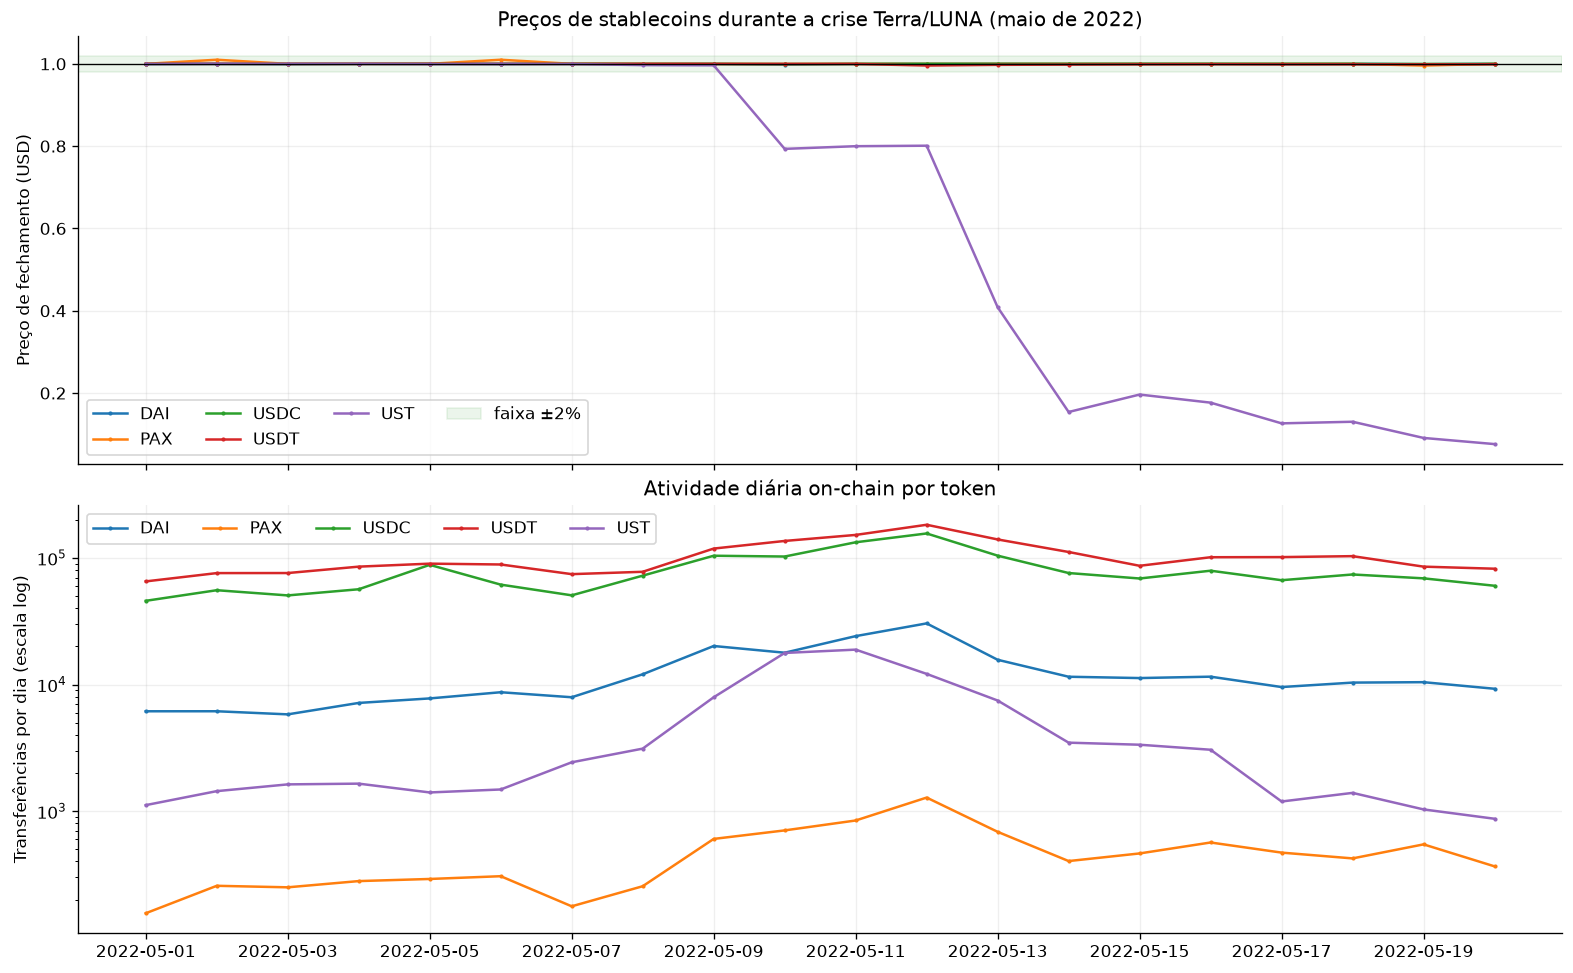

In [12]:
# Comparação de preços e atividade durante o choque de maio de 2022
window_start = pd.Timestamp("2022-05-01", tz="UTC")
window_end = pd.Timestamp("2022-05-20", tz="UTC")
price_window = snap_prices.loc[snap_prices["date"].between(window_start, window_end)]
flow_window = snap_daily_transfers.loc[snap_daily_transfers["date"].between(window_start, window_end)]

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True, constrained_layout=True)
for token, group in price_window.groupby("token"):
    if token != "WLUNA":
        axes[0].plot(group["date"], group["close"], marker=".", markersize=3, label=token)
axes[0].axhspan(0.98, 1.02, color="green", alpha=0.08, label="faixa ±2%")
axes[0].axhline(1.0, color="black", linewidth=0.8)
axes[0].set_ylabel("Preço de fechamento (USD)")
axes[0].set_title("Preços de stablecoins durante a crise Terra/LUNA (maio de 2022)")
axes[0].legend(ncol=4)
axes[0].grid(alpha=0.2)

for token, group in flow_window.groupby("token"):
    axes[1].plot(group["date"], group["transfer_count"], marker=".", markersize=3, label=token)
axes[1].set_yscale("log")
axes[1].set_ylabel("Transferências por dia (escala log)")
axes[1].set_title("Atividade diária on-chain por token")
axes[1].legend(ncol=5)
axes[1].grid(alpha=0.2)
plt.show()


### Leitura do monitor SNAP

Os alertas indicam que o preço observado saiu da faixa de paridade configurada e deve ser revisado junto às evidências de mercado e atividade on-chain. A coincidência temporal entre desvio, transferências e um evento catalogado é **associação descritiva**, não causalidade nem prova de fraude. As transferências são agregadas diariamente; uma decisão sobre uma transação individual exigiria cotação contemporânea, liquidez, contexto do protocolo e evidência da carteira/operação.

O detector de *pump and dump* do Arick é complementar, mas separado: ele exige negócios de mercado com preço, quantidade, lado agressor e horários de pumps documentados. O dataset SNAP não substitui esses dados nem serve para treinar aquele classificador.
